# Customer Churn Analysis

## Business Objective

Analyze customer data to identify factors associated with customer churn and generate actionable insights that can help improve customer retention.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_csv("../Data/Telco-Customer-Churn.csv")

df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['TotalCharges'].dtype

dtype('O')

In [10]:
df_clean = df.copy()

In [11]:
df_clean['TotalCharges'].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object

In [12]:
pd.to_numeric(df_clean['TotalCharges'], errors='coerce').isna().sum()

np.int64(11)

In [13]:
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

In [14]:
df_clean['TotalCharges'].dtype

dtype('float64')

In [15]:
df_clean['TotalCharges'].isnull().sum()

np.int64(11)

In [16]:
df_clean[df_clean['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [17]:
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

In [18]:
df_clean.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [19]:
df_clean['SeniorCitizen_Label'] = df_clean['SeniorCitizen'].map({0:'No', 1:'Yes'})

In [20]:
df_clean['SeniorCitizen_Label'].value_counts()

SeniorCitizen_Label
No     5901
Yes    1142
Name: count, dtype: int64

In [21]:
df_clean['TenureGroup'] = pd.cut(
    df_clean['tenure'],
    bins=[-1, 12, 24, 48, 60, 100],
    labels=['0-1 Year', '1-2 Year', '2-4 Year', '4-5 Year', '5+ Year']
)

In [22]:
df_clean['TenureGroup'].value_counts().sort_index()

TenureGroup
0-1 Year    2186
1-2 Year    1024
2-4 Year    1594
4-5 Year     832
5+ Year     1407
Name: count, dtype: int64

In [23]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   customerID           7043 non-null   object  
 1   gender               7043 non-null   object  
 2   SeniorCitizen        7043 non-null   int64   
 3   Partner              7043 non-null   object  
 4   Dependents           7043 non-null   object  
 5   tenure               7043 non-null   int64   
 6   PhoneService         7043 non-null   object  
 7   MultipleLines        7043 non-null   object  
 8   InternetService      7043 non-null   object  
 9   OnlineSecurity       7043 non-null   object  
 10  OnlineBackup         7043 non-null   object  
 11  DeviceProtection     7043 non-null   object  
 12  TechSupport          7043 non-null   object  
 13  StreamingTV          7043 non-null   object  
 14  StreamingMovies      7043 non-null   object  
 15  Contract             

In [24]:
df_clean.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,SeniorCitizen_Label,TenureGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,No,0-1 Year
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,No,2-4 Year
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,No,0-1 Year
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,No,2-4 Year
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,No,0-1 Year


In [25]:
df_clean['TotalCharges'].isnull().sum()

np.int64(0)

In [26]:
total_customers = df_clean['customerID'].nunique()

print("Total Customers:", total_customers)

Total Customers: 7043


In [27]:
churned_customers = (df_clean['Churn'] == 'Yes').sum()

print("Churned Customers:", churned_customers)

Churned Customers: 1869


In [28]:
churn_rate = (churned_customers / total_customers) * 100

print("Churn Rate:", round(churn_rate, 2), "%")

Churn Rate: 26.54 %


In [29]:
retained_customers = (df_clean['Churn'] == 'No').sum()

print("Retained Customers:", retained_customers)

Retained Customers: 5174


In [30]:
total_monthly_charges = df_clean['MonthlyCharges'].sum()

print("Total Monthly Charges:", round(total_monthly_charges, 2))

Total Monthly Charges: 456116.6


In [31]:
avg_monthly_charges = df_clean['MonthlyCharges'].mean()

print("Average Monthly Charges:", round(avg_monthly_charges, 2))

Average Monthly Charges: 64.76


In [32]:
total_customer_charges = df_clean['TotalCharges'].sum()

print("Total Customer Charges:", round(total_customer_charges, 2))

Total Customer Charges: 16056168.7


In [33]:
avg_tenure = df_clean['tenure'].mean()

print("Average Customer Tenure:", round(avg_tenure, 2), "months")

Average Customer Tenure: 32.37 months


In [34]:
kpi_summary = {
    'Total Customers': total_customers,
    'Churned Customers': churned_customers,
    'Retained Customers': retained_customers,
    'Churn Rate (%)': round(churn_rate, 2),
    'Total Monthly Charges': round(total_monthly_charges, 2),
    'Average Monthly Charges': round(avg_monthly_charges, 2),
    'Total Customer Charges': round(total_customer_charges, 2),
    'Average Tenure (Months)': round(avg_tenure, 2)
}

kpi_summary

{'Total Customers': 7043,
 'Churned Customers': np.int64(1869),
 'Retained Customers': np.int64(5174),
 'Churn Rate (%)': np.float64(26.54),
 'Total Monthly Charges': np.float64(456116.6),
 'Average Monthly Charges': np.float64(64.76),
 'Total Customer Charges': np.float64(16056168.7),
 'Average Tenure (Months)': np.float64(32.37)}

In [35]:
df_clean['TotalCharges'].isnull().sum()

np.int64(0)

In [36]:
churn_count = df_clean['Churn'].value_counts()

print(churn_count)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [37]:
churn_percentage = df_clean['Churn'].value_counts(normalize=True) * 100

print(churn_percentage.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


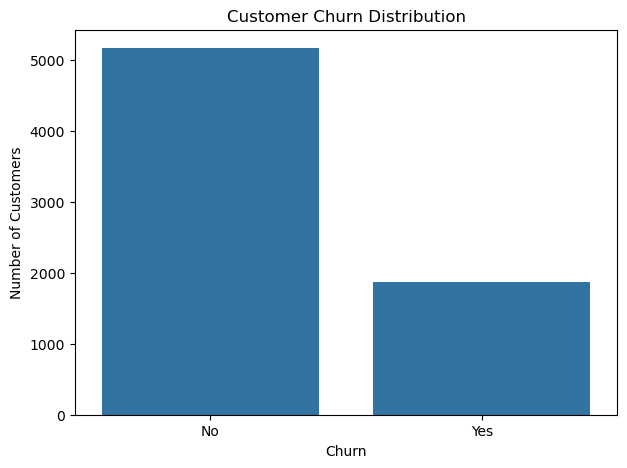

In [38]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.savefig("../images/Customer Churn Distribution.png", bbox_inches='tight')

plt.show()

In [39]:
# Which contract type has the highest churn?
contract_churn = pd.crosstab(
    df_clean['Contract'],
    df_clean['Churn']
)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [40]:
contract_churn_rate = pd.crosstab(
    df_clean['Contract'],
    df_clean['Churn'],
    normalize='index'
) * 100

contract_churn_rate.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


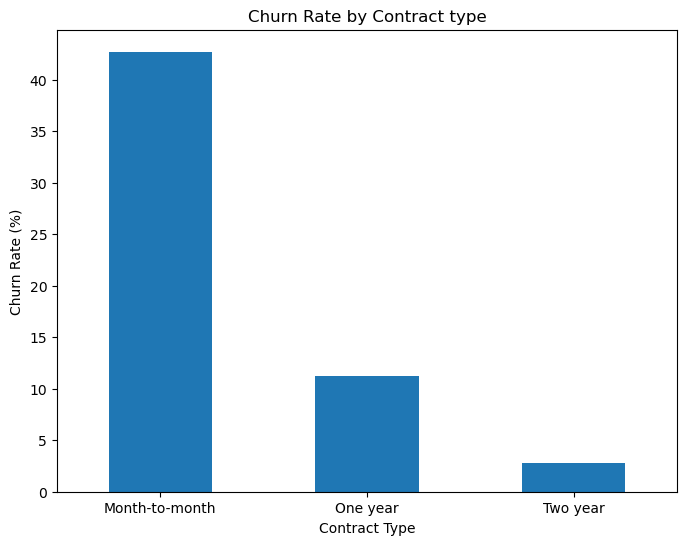

In [41]:
contract_churn_rate['Yes'].sort_values(ascending=False).plot(kind='bar', figsize=(8, 6))

plt.title('Churn Rate by Contract type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.savefig("../images/Churn Rate by Contract type.png", bbox_inches='tight')

plt.show()


In [42]:
tenure_churn = pd.crosstab(
    df_clean['TenureGroup'],
    df_clean['Churn'],
    normalize='index'
) * 100

tenure_churn.round(2)

Churn,No,Yes
TenureGroup,,
0-1 Year,52.56,47.44
1-2 Year,71.29,28.71
2-4 Year,79.61,20.39
4-5 Year,85.58,14.42
5+ Year,93.39,6.61


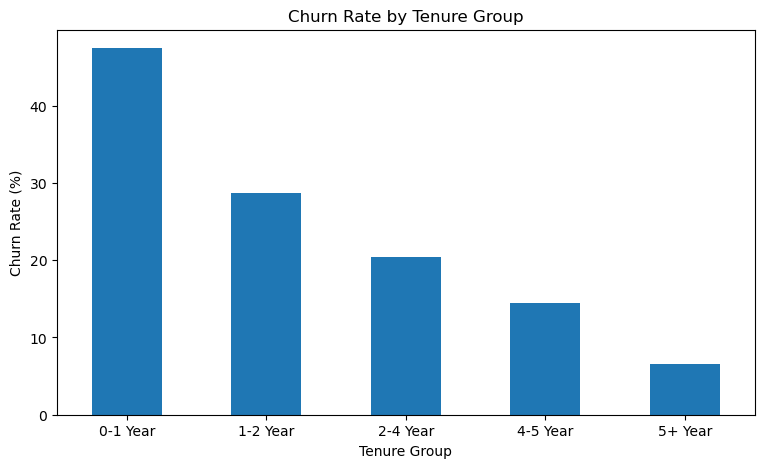

In [43]:
tenure_churn['Yes'].plot(kind='bar', figsize=(9, 5))

plt.title('Churn Rate by Tenure Group')
plt.xlabel('Tenure Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.savefig("../images/Churn Rate by Tenure Group.png", bbox_inches='tight')

plt.show()


In [44]:
# Does the type of internet service affect customer churn?
internet_churn = pd.crosstab(
    df_clean['InternetService'],
    df_clean['Churn'],
    normalize = 'index'
) * 100

internet_churn.round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


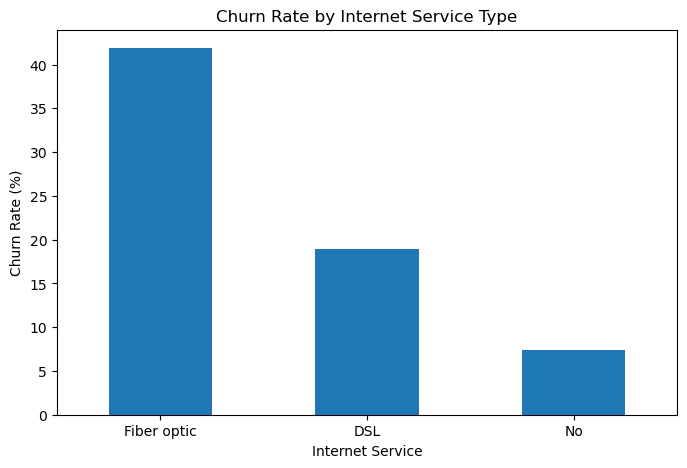

In [45]:
internet_churn['Yes'].sort_values(ascending=False).plot(kind='bar', figsize=(8,5))

plt.title('Churn Rate by Internet Service Type')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.savefig("../images/Churn Rate by Internet Service Type.png", bbox_inches='tight')

plt.show()


In [46]:
payment_churn = pd.crosstab(
    df_clean['PaymentMethod'],
    df_clean['Churn'],
    normalize='index'
) * 100

payment_churn.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [47]:
highest_internet_churn = internet_churn['Yes'].idxmax()
highest_internet_rate = internet_churn['Yes'].max()

print("Highest Churn Internet Service:", highest_internet_churn)
print("Highest Churn Rate:", round(highest_internet_rate, 2), "%")

Highest Churn Internet Service: Fiber optic
Highest Churn Rate: 41.89 %


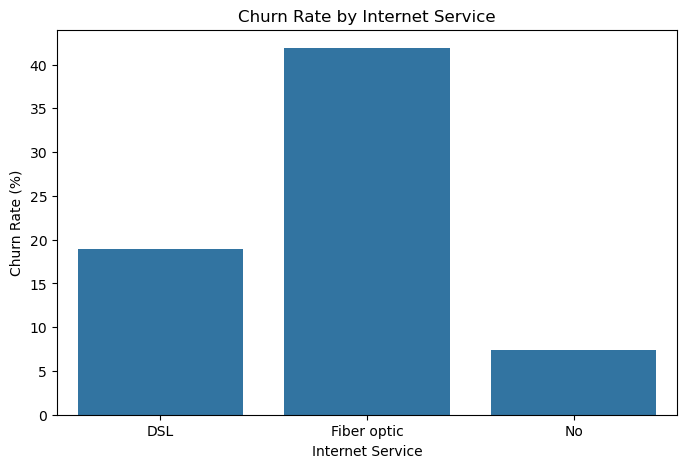

In [48]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn['Yes'].values
)

plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.savefig("../images/Churn Rate by Internet Service.png", bbox_inches='tight')

plt.show()

In [49]:
payment_churn.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [50]:
# Churn by Monthly Charges
df_clean['MonthlyChargegroup'] = pd.cut(
    df_clean['MonthlyCharges'],
    bins = [0, 30, 60, 90, 120],
    labels = ['0-30', '31-60', '61-90', '91-120']
)

In [51]:
df_clean['MonthlyChargegroup'].value_counts().sort_index()

MonthlyChargegroup
0-30      1653
31-60     1265
61-90     2386
91-120    1739
Name: count, dtype: int64

In [52]:
charge_churn = pd.crosstab(
    df_clean['MonthlyChargegroup'],
    df_clean['Churn'],
    normalize = 'index'
) * 100

charge_churn.round(2)

Churn,No,Yes
MonthlyChargegroup,,
0-30,90.20,9.80
31-60,74.07,25.93
61-90,66.09,33.91
91-120,67.22,32.78


In [53]:
highest_charge_churn = charge_churn['Yes'].idxmax()
highest_charge_rate = charge_churn['Yes'].max()

print("Highest Churn Charge Group:", highest_charge_churn)
print("Highest Churn Rate:", round(highest_charge_rate, 2), "%")

Highest Churn Charge Group: 61-90
Highest Churn Rate: 33.91 %


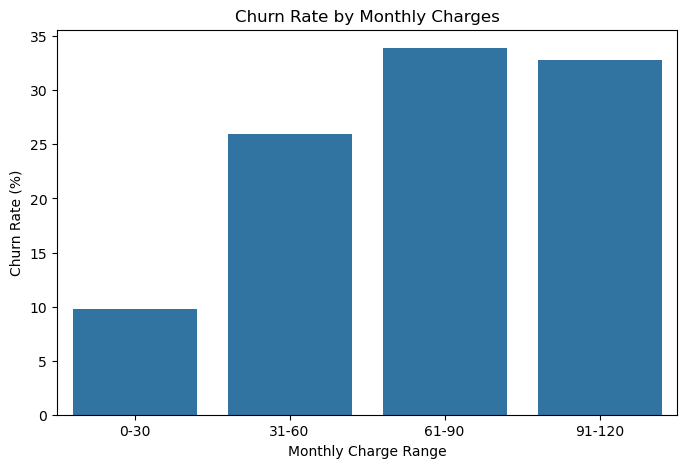

In [54]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=charge_churn.index,
    y=charge_churn['Yes'].values
)

plt.title('Churn Rate by Monthly Charges')
plt.xlabel('Monthly Charge Range')
plt.ylabel('Churn Rate (%)')
plt.savefig("../images/Churn Rate by Monthly Charges.png", bbox_inches='tight')

plt.show()

In [55]:
# Churn by Tech Support
# Are customers without Tech Support more likely to churn?
techsupport_churn = pd.crosstab(
    df_clean['TechSupport'],
    df_clean['Churn'],
    normalize = 'index'
) * 100

techsupport_churn.round(2)

Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


In [56]:
highest_support_churn = techsupport_churn['Yes'].idxmax()
highest_support_rate = techsupport_churn['Yes'].max()

print("Highest Churn Tech Support Group:", highest_support_churn)
print("Highest Churn Rate:", round(highest_support_rate, 2), "%")

Highest Churn Tech Support Group: No
Highest Churn Rate: 41.64 %


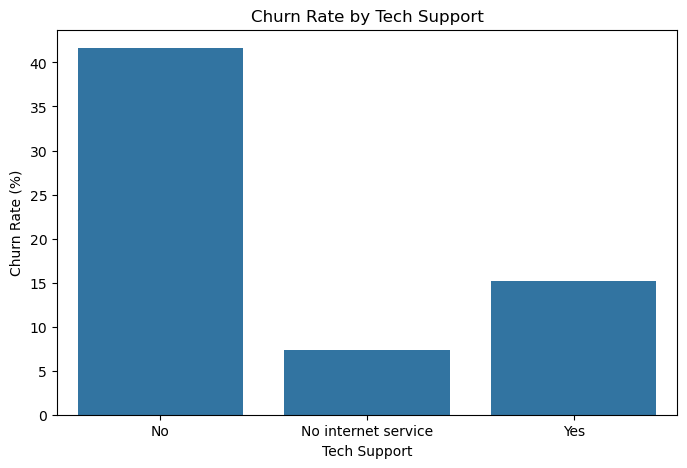

In [57]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=techsupport_churn.index,
    y=techsupport_churn['Yes'].values
)

plt.title('Churn Rate by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Churn Rate (%)')
plt.savefig("../images/Churn Rate by Tech Support.png", bbox_inches='tight')

plt.show()

In [58]:
# Churn by Online Security
# Do customers without Online Security have higher churn?
security_churn = pd.crosstab(
    df_clean['OnlineSecurity'],
    df_clean['Churn'],
    normalize = 'index'
) * 100

security_churn.round(2)

Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


In [59]:
highest_security_churn = security_churn['Yes'].idxmax()
highest_security_rate = security_churn['Yes'].max()

print("Highest Churn Online Security Group:", highest_security_churn)
print("Highest Churn Rate:", round(highest_security_rate, 2), "%")

Highest Churn Online Security Group: No
Highest Churn Rate: 41.77 %


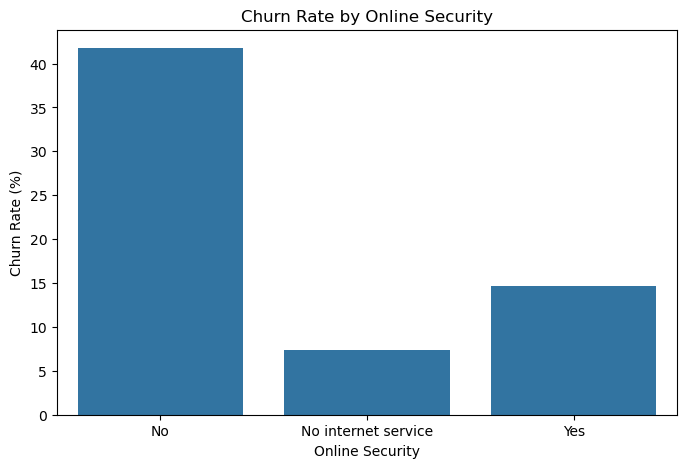

In [60]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=security_churn.index,
    y=security_churn['Yes'].values
)

plt.title('Churn Rate by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Churn Rate (%)')
plt.savefig("../images/Churn Rate by Online Security.png", bbox_inches='tight')

plt.show()

In [61]:
# Advanced Customer Segmentation
# Create a churn-rate matrix

contract_tenure_churn = pd.crosstab(
    [df_clean['Contract'], df_clean['TenureGroup']],
    df_clean['Churn'],
    normalize='index'
) * 100

contract_tenure_churn.round(2)

Churn                           No    Yes
Contract       TenureGroup               
Month-to-month 0-1 Year      48.65  51.35
               1-2 Year      62.28  37.72
               2-4 Year      67.08  32.92
               4-5 Year      72.22  27.78
               5+ Year       77.78  22.22
One year       0-1 Year      89.52  10.48
               1-2 Year      91.88   8.12
               2-4 Year      89.38  10.62
               4-5 Year      86.29  13.71
               5+ Year       87.86  12.14
Two year       0-1 Year     100.00   0.00
               1-2 Year     100.00   0.00
               2-4 Year      97.81   2.19
               4-5 Year      96.03   3.97
               5+ Year       96.86   3.14

In [62]:
# Display only churned percentage

contract_tenure_churn_yes = (
    contract_tenure_churn['Yes'].reset_index().sort_values('Yes', ascending=False)
)

contract_tenure_churn_yes

,Contract,TenureGroup,Yes
0,Month-to-month,0-1 Year,51.354062
1,Month-to-month,1-2 Year,37.720488
2,Month-to-month,2-4 Year,32.917706
3,Month-to-month,4-5 Year,27.777778
4,Month-to-month,5+ Year,22.222222
8,One year,4-5 Year,13.707165
9,One year,5+ Year,12.140575
7,One year,2-4 Year,10.617761
5,One year,0-1 Year,10.483871
6,One year,1-2 Year,8.121827


In [63]:
# Find the highest-risk segment
highest_risk_segment = contract_tenure_churn_yes.iloc[0]

print("Highest Risk Contract:", highest_risk_segment['Contract'])
print("Highest Risk Tenure Group:", highest_risk_segment['TenureGroup'])
print("Churn Rate:", round(highest_risk_segment['Yes'], 2), "%")

Highest Risk Contract: Month-to-month
Highest Risk Tenure Group: 0-1 Year
Churn Rate: 51.35 %


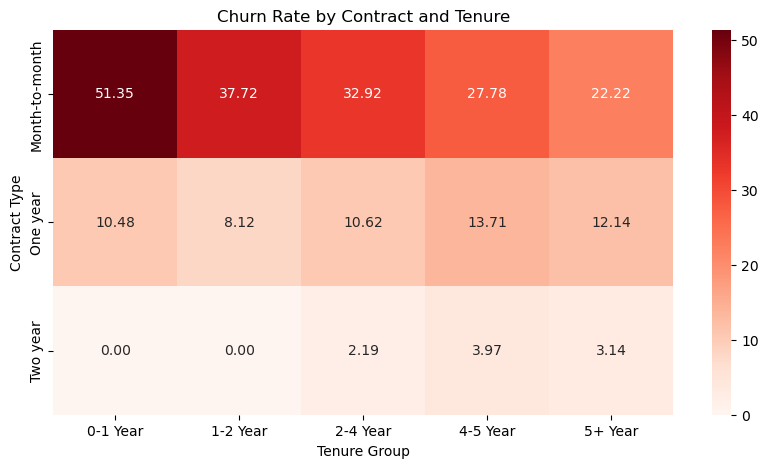

In [64]:
heatmap_data = contract_tenure_churn['Yes'].unstack()

plt.figure(figsize=(10, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='Reds'
)

plt.title('Churn Rate by Contract and Tenure')
plt.xlabel('Tenure Group')
plt.ylabel('Contract Type')
plt.savefig("../images/Churn Rate by Contract and Tenure.png", bbox_inches='tight')

plt.show()

In [65]:
service_columns = [
    'PhoneService',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

df_clean['TotalServices'] = 0

for col in service_columns:
    df_clean['TotalServices'] += (
        df_clean[col].isin(['Yes', 'Yes', 'No internet service'])
    ).astype(int)

df_clean[['TotalServices', 'Churn']].head()

,TotalServices,Churn
0,1,No
1,3,No
2,3,Yes
3,3,No
4,1,Yes


In [66]:
service_churn = pd.crosstab(
    df_clean['TotalServices'],
    df_clean['Churn'],
    normalize='index'
) * 100

service_churn.round(2)

Churn,No,Yes
TotalServices,,
0,56.25,43.75
1,50.48,49.52
2,55.08,44.92
3,63.52,36.48
4,68.66,31.34
5,74.45,25.55
6,77.51,22.49
7,90.37,9.63
8,96.18,3.82


In [67]:
highest_service_churn = service_churn['Yes'].idxmax()
highest_service_rate = service_churn['Yes'].max()

print("Highest Churn Service Group:", highest_service_churn)
print("Highest Churn Rate:", round(highest_service_rate, 2), "%")

Highest Churn Service Group: 1
Highest Churn Rate: 49.52 %


In [68]:
# Customer Risk Segmentation

df_clean['RiskScore'] = 0

# month-to-month contract
df_clean.loc[
    df_clean['Contract'] == 'Month-to-month', 'RiskScore'
] += 2

# New customers
df_clean.loc[
    df_clean['tenure'] <= 12, 'RiskScore'
] += 2

# High monthly charges
df_clean.loc[
    df_clean['MonthlyCharges'] > 70, 'RiskScore'
] += 1

# No tech support
df_clean.loc[
    df_clean['TechSupport'] == 'No',
    'RiskScore'
] += 1

# No online security
df_clean.loc[
    df_clean['OnlineSecurity'] == 'No',
    'RiskScore'
] += 1

In [69]:
df_clean['RiskSegment'] = pd.cut(
    df_clean['RiskScore'],
    bins=[-1, 2, 4, 7],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

In [70]:
risk_churn = pd.crosstab(
    df_clean['RiskSegment'],
    df_clean['Churn'],
    normalize='index'
) * 100

risk_churn.round(2)

Churn,No,Yes
RiskSegment,,
Low Risk,94.27,5.73
Medium Risk,75.66,24.34
High Risk,44.48,55.52


In [71]:
print("Churn Rate by Risk Segment:")
print(risk_churn['Yes'].round(2))

Churn Rate by Risk Segment:
RiskSegment
Low Risk        5.73
Medium Risk    24.34
High Risk      55.52
Name: Yes, dtype: float64


In [72]:
import sqlite3

conn = sqlite3.connect('customer_churn.db')

df_clean.to_sql(
    'customers',
    conn,
    if_exists='replace',
    index=False
)

print("Data loaded successfully into SQLite.")

Data loaded successfully into SQLite.


In [73]:
query = """
SELECT COUNT(*) AS total_customers
FROM customers;
"""

result = pd.read_sql_query(query, conn)

result

,total_customers
0,7043


In [74]:
# Total Customers & Churn Rate
query = """
SELECT
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    SUM(CASE WHEN Churn = 'No' THEN 1 ELSE 0 END) AS retained_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS churn_rate
FROM customers;
"""

result = pd.read_sql_query(query, conn)

result

,total_customers,churned_customers,retained_customers,churn_rate
0,7043,1869,5174,26.54


In [75]:
# Churn by Contract
query = """
SELECT
    Contract,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS churn_rate
FROM customers
GROUP BY Contract
ORDER BY churn_rate DESC;
"""

contract_sql = pd.read_sql_query(query, conn)

contract_sql

,Contract,total_customers,churned_customers,churn_rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [76]:
# Churn by Payment Method
query = """
SELECT
    PaymentMethod,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS churn_rate
FROM customers
GROUP BY PaymentMethod
ORDER BY churn_rate DESC;
"""

payment_sql = pd.read_sql_query(query, conn)

payment_sql

,PaymentMethod,total_customers,churned_customers,churn_rate
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


In [77]:
# Churn by Internet Service
query = """
SELECT
    InternetService,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS churn_rate
FROM customers
GROUP BY InternetService
ORDER BY churn_rate DESC;
"""

internet_sql = pd.read_sql_query(query, conn)

internet_sql

,InternetService,total_customers,churned_customers,churn_rate
0,Fiber optic,3096,1297,41.89
1,DSL,2421,459,18.96
2,No,1526,113,7.40


In [78]:
# Churn by Tenure Group
query = """
SELECT
    TenureGroup,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS churn_rate
FROM customers
GROUP BY TenureGroup
ORDER BY churn_rate DESC;
"""

tenure_sql = pd.read_sql_query(query, conn)

tenure_sql

,TenureGroup,total_customers,churned_customers,churn_rate
0,0-1 Year,2186,1037,47.44
1,1-2 Year,1024,294,28.71
2,2-4 Year,1594,325,20.39
3,4-5 Year,832,120,14.42
4,5+ Year,1407,93,6.61


In [79]:
# High-Value Customers Who Churned
query = """
SELECT
    customerID,
    Contract,
    tenure,
    MonthlyCharges,
    TotalCharges,
    PaymentMethod,
    InternetService
FROM customers
WHERE Churn = 'Yes'
ORDER BY MonthlyCharges DESC
LIMIT 10;
"""

high_value_churned = pd.read_sql_query(query, conn)

high_value_churned

,customerID,Contract,tenure,MonthlyCharges,TotalCharges,PaymentMethod,InternetService
0,8199-ZLLSA,One year,67,118.35,7804.15,Bank transfer (automatic),Fiber optic
1,2889-FPWRM,One year,72,117.80,8684.80,Bank transfer (automatic),Fiber optic
2,2302-ANTDP,Month-to-month,48,117.45,5438.90,Electronic check,Fiber optic
3,9053-JZFKV,Two year,67,116.20,7752.30,Credit card (automatic),Fiber optic
4,1444-VVSGW,One year,70,115.65,7968.85,Credit card (automatic),Fiber optic
5,0201-OAMXR,One year,70,115.55,8127.60,Credit card (automatic),Fiber optic
6,4361-BKAXE,Month-to-month,41,114.50,4527.45,Bank transfer (automatic),Fiber optic
7,1555-DJEQW,Two year,70,114.20,7723.90,Bank transfer (automatic),Fiber optic
8,9158-VCTQB,Month-to-month,41,113.60,4594.95,Bank transfer (automatic),Fiber optic
9,7279-BUYWN,Month-to-month,41,113.20,4689.50,Electronic check,Fiber optic


In [80]:
# Identify High-Risk Customers
query = """
SELECT
    customerID,
    tenure,
    Contract,
    MonthlyCharges,
    TotalCharges,
    PaymentMethod,
    InternetService,
    TechSupport,
    OnlineSecurity,
    Churn
FROM customers
WHERE Contract = 'Month-to-month'
  AND tenure <= 12
  AND MonthlyCharges >= 70
ORDER BY MonthlyCharges DESC;
"""

high_risk_customers = pd.read_sql_query(query, conn)

high_risk_customers.head(20)

,customerID,tenure,Contract,MonthlyCharges,TotalCharges,PaymentMethod,InternetService,TechSupport,OnlineSecurity,Churn
0,1583-IHQZE,12,Month-to-month,112.95,1384.75,Mailed check,Fiber optic,Yes,No,Yes
1,3292-PBZEJ,11,Month-to-month,111.40,1183.05,Electronic check,Fiber optic,Yes,No,No
2,9851-KIELU,10,Month-to-month,110.10,1043.30,Electronic check,Fiber optic,Yes,Yes,Yes
3,3992-YWPKO,6,Month-to-month,109.90,669.45,Credit card (automatic),Fiber optic,Yes,No,Yes
4,5760-IFJOZ,3,Month-to-month,107.95,313.60,Mailed check,Fiber optic,No,No,No
5,2081-VEYEH,3,Month-to-month,107.95,318.60,Electronic check,Fiber optic,Yes,No,No
6,2027-FECZV,12,Month-to-month,106.70,1253.90,Electronic check,Fiber optic,No,No,Yes
7,1400-MMYXY,3,Month-to-month,105.90,334.65,Electronic check,Fiber optic,No,No,Yes
8,3389-YGYAI,8,Month-to-month,105.50,829.55,Electronic check,Fiber optic,No,No,Yes
9,5052-PNLOS,3,Month-to-month,105.35,323.25,Bank transfer (automatic),Fiber optic,No,No,Yes


In [81]:
query = """
SELECT
    COUNT(*) AS high_risk_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS churn_rate
FROM customers
WHERE Contract = 'Month-to-month'
  AND tenure <= 12
  AND MonthlyCharges >= 70;
"""

high_risk_summary = pd.read_sql_query(query, conn)

high_risk_summary

,high_risk_customers,churned_customers,churn_rate
0,860,595,69.19


In [82]:
# Customer Value by Contract
query = """
SELECT
    Contract,
    COUNT(*) AS total_customers,
    ROUND(AVG(MonthlyCharges), 2) AS avg_monthly_charges,
    ROUND(SUM(MonthlyCharges), 2) AS total_monthly_revenue,
    ROUND(AVG(TotalCharges), 2) AS avg_total_charges
FROM customers
GROUP BY Contract
ORDER BY total_monthly_revenue DESC;
"""

contract_value = pd.read_sql_query(query, conn)
contract_value

,Contract,total_customers,avg_monthly_charges,total_monthly_revenue,avg_total_charges
0,Month-to-month,3875,66.40,257294.15,1369.25
1,Two year,1695,60.77,103005.85,3706.93
2,One year,1473,65.05,95816.60,3032.62


In [83]:
query = """
SELECT
    TotalServices,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS churn_rate
FROM customers
GROUP BY TotalServices
ORDER BY TotalServices;
"""

service_churn = pd.read_sql_query(query, conn)
service_churn

,TotalServices,total_customers,churned_customers,churn_rate
0,0,80,35,43.75
1,1,517,256,49.52
2,2,846,380,44.92
3,3,965,352,36.48
4,4,922,289,31.34
5,5,908,232,25.55
6,6,676,152,22.49
7,7,1579,152,9.63
8,8,550,21,3.82


In [84]:
query = """
SELECT
    Contract,
    TenureGroup,
    PaymentMethod,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS churn_rate
FROM customers
GROUP BY Contract, TenureGroup, PaymentMethod
HAVING COUNT(*) >= 20
ORDER BY churn_rate DESC
LIMIT 10;
"""

final_risk_summary = pd.read_sql_query(query, conn)
final_risk_summary

,Contract,TenureGroup,PaymentMethod,total_customers,churned_customers,churn_rate
0,Month-to-month,0-1 Year,Electronic check,954,602,63.10
1,Month-to-month,1-2 Year,Electronic check,355,182,51.27
2,Month-to-month,0-1 Year,Bank transfer (automatic),208,101,48.56
3,Month-to-month,0-1 Year,Credit card (automatic),191,79,41.36
4,Month-to-month,2-4 Year,Electronic check,376,154,40.96
5,Month-to-month,0-1 Year,Mailed check,641,242,37.75
6,Month-to-month,4-5 Year,Electronic check,116,43,37.07
7,Month-to-month,1-2 Year,Credit card (automatic),121,38,31.40
8,Month-to-month,2-4 Year,Bank transfer (automatic),172,52,30.23
9,Month-to-month,2-4 Year,Credit card (automatic),159,44,27.67


In [85]:
df_clean.to_csv(
    '../data/cleaned_customer_churn.csv',
    index=False
)